# 05 - Practice: Sales Dashboard
We build a fake sales dataset, then make **time series**, **comparison**, and **dashboard** visualizations.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
from plotly.subplots import make_subplots
import plotly.graph_objects as go

np.random.seed(10)
sns.set_theme(style='whitegrid')

dates = pd.date_range('2024-01-01', '2025-12-31', freq='D')
rows = []
for d in dates:
    for region in ['North', 'South', 'East', 'West']:
        for cat in ['Electronics', 'Clothing', 'Home']:
            base = {'Electronics': 300, 'Clothing': 150, 'Home': 100}[cat]
            season = 1 + 0.3 * np.sin(2 * np.pi * d.dayofyear / 365)
            growth = 1 + (d - dates[0]).days / 1500
            units = max(1, int(np.random.poisson(base / 20) * season * growth))
            price = {'Electronics': 20, 'Clothing': 8, 'Home': 12}[cat]
            rows.append((d, region, cat, units, units * price))
sales = pd.DataFrame(rows, columns=['date', 'region', 'category', 'units', 'revenue'])
sales['month'] = sales['date'].dt.to_period('M').dt.to_timestamp()
sales['year'] = sales['date'].dt.year
print(sales.shape)
sales.head()

(8772, 7)


,date,region,category,units,revenue,month,year
0,2024-01-01,North,Electronics,18,360,2024-01-01,2024
1,2024-01-01,North,Clothing,7,56,2024-01-01,2024
2,2024-01-01,North,Home,2,24,2024-01-01,2024
3,2024-01-01,South,Electronics,15,300,2024-01-01,2024
4,2024-01-01,South,Clothing,10,80,2024-01-01,2024


## Part A - Time series plots

### A1. Monthly revenue trend

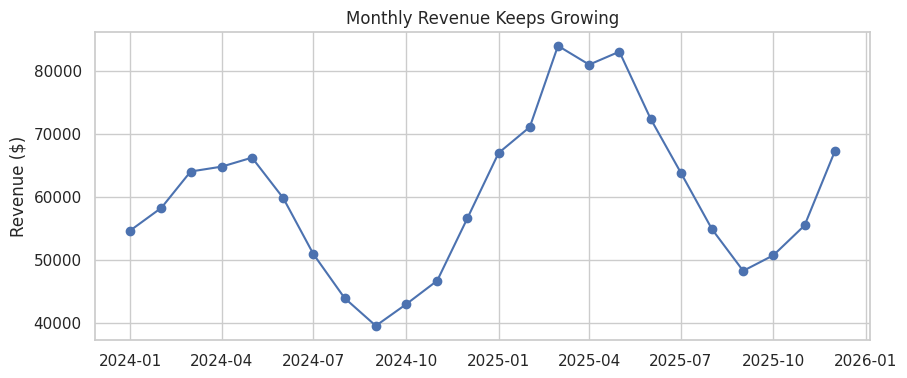

In [2]:
monthly = sales.groupby('month')['revenue'].sum()
plt.figure(figsize=(10, 4))
plt.plot(monthly.index, monthly.values, marker='o')
plt.title('Monthly Revenue Keeps Growing')
plt.ylabel('Revenue ($)')
plt.show()

### A2. Daily data with 30-day moving average

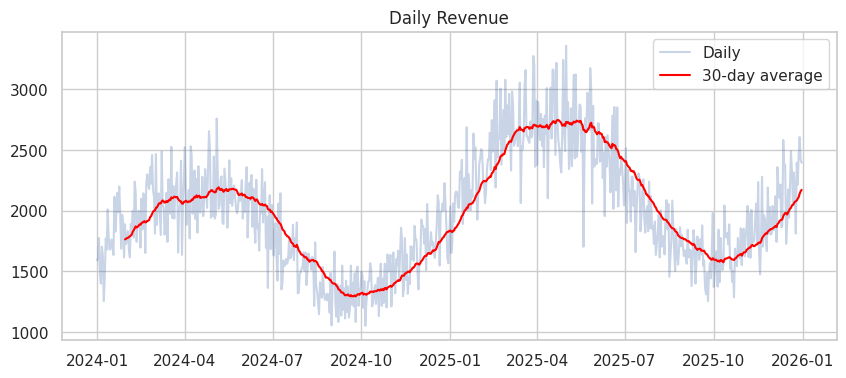

In [3]:
daily = sales.groupby('date')['revenue'].sum()
plt.figure(figsize=(10, 4))
plt.plot(daily.index, daily.values, alpha=0.3, label='Daily')
plt.plot(daily.index, daily.rolling(30).mean(), color='red', label='30-day average')
plt.title('Daily Revenue')
plt.legend()
plt.show()

### A3. Year-over-year comparison

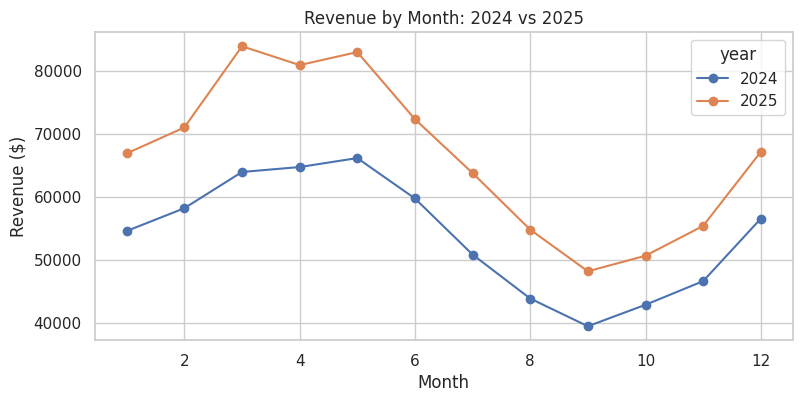

In [4]:
yoy = sales.assign(m=sales['date'].dt.month).groupby(['m', 'year'])['revenue'].sum().unstack()
yoy.plot(marker='o', figsize=(9, 4))
plt.title('Revenue by Month: 2024 vs 2025')
plt.xlabel('Month')
plt.ylabel('Revenue ($)')
plt.show()

### A4. Revenue by category over time (stacked area)

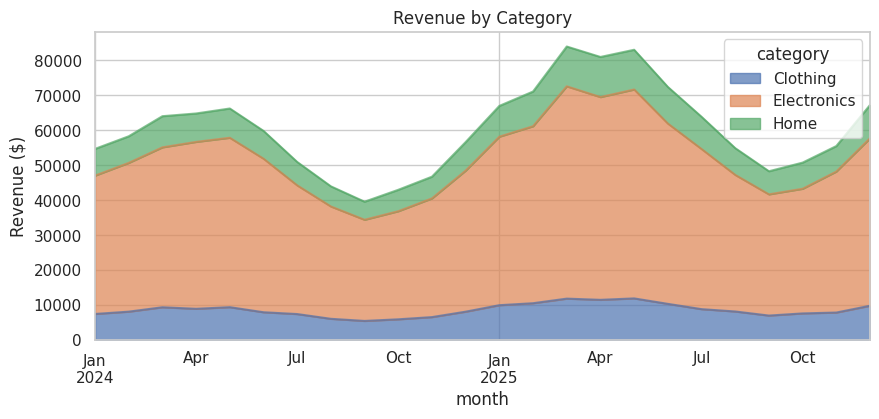

In [5]:
cat_month = sales.groupby(['month', 'category'])['revenue'].sum().unstack()
cat_month.plot.area(figsize=(10, 4), alpha=0.7)
plt.title('Revenue by Category')
plt.ylabel('Revenue ($)')
plt.show()

## Part B - Comparison charts

### B1. Revenue by region

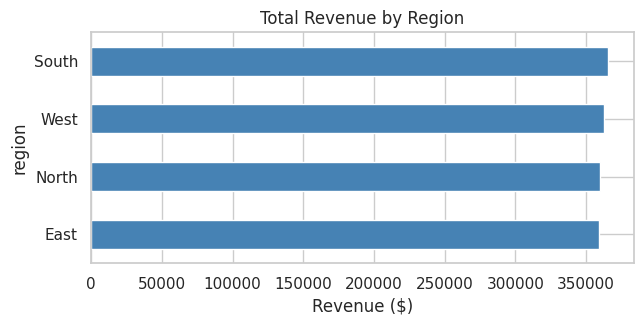

In [6]:
reg = sales.groupby('region')['revenue'].sum().sort_values()
reg.plot.barh(color='steelblue', figsize=(7, 3))
plt.title('Total Revenue by Region')
plt.xlabel('Revenue ($)')
plt.show()

### B2. Region x Category (grouped bars)

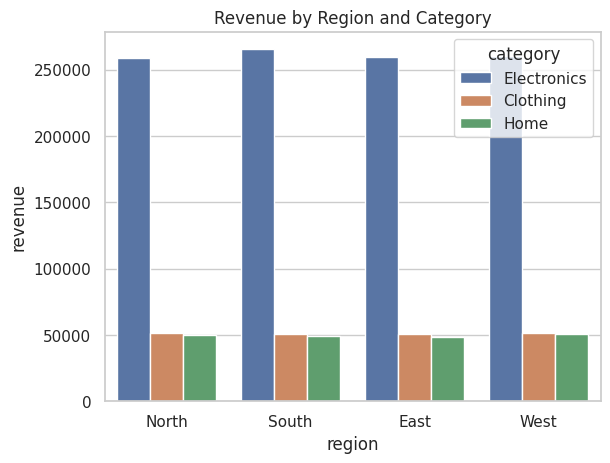

In [7]:
sns.barplot(data=sales, x='region', y='revenue', hue='category', estimator='sum', errorbar=None)
plt.title('Revenue by Region and Category')
plt.show()

### B3. Heatmap: month x region

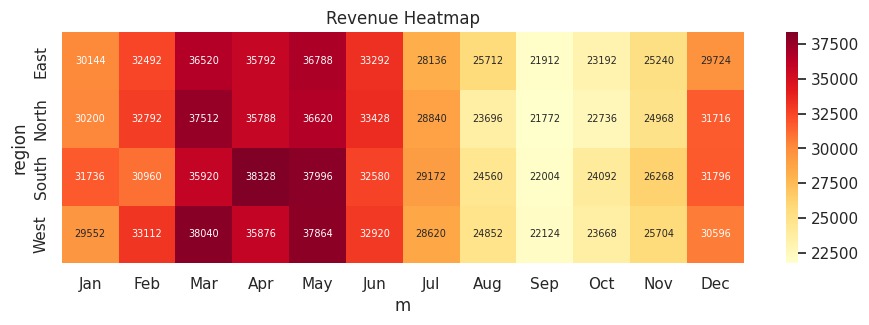

In [8]:
heat = sales.assign(m=sales['date'].dt.month_name().str[:3]).pivot_table(
    index='region', columns='m', values='revenue', aggfunc='sum')
heat = heat[['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec']]
plt.figure(figsize=(11, 3))
sns.heatmap(heat, cmap='YlOrRd', annot=True, fmt='.0f', annot_kws={'size': 7})
plt.title('Revenue Heatmap')
plt.show()

### B4. Distribution of daily revenue per region

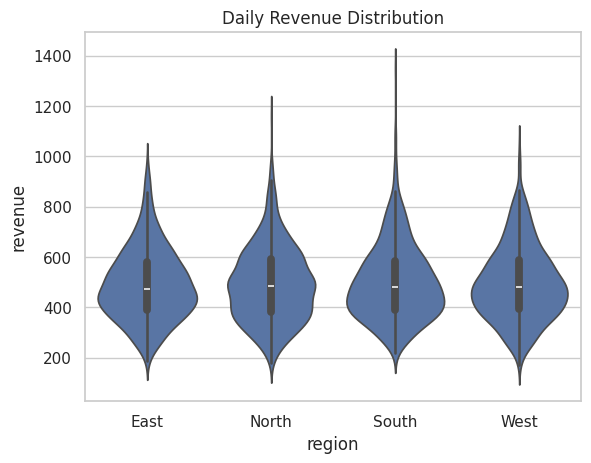

In [9]:
d = sales.groupby(['date', 'region'], as_index=False)['revenue'].sum()
sns.violinplot(data=d, x='region', y='revenue')
plt.title('Daily Revenue Distribution')
plt.show()

## Part C - Matplotlib dashboard (one figure, 4 charts)

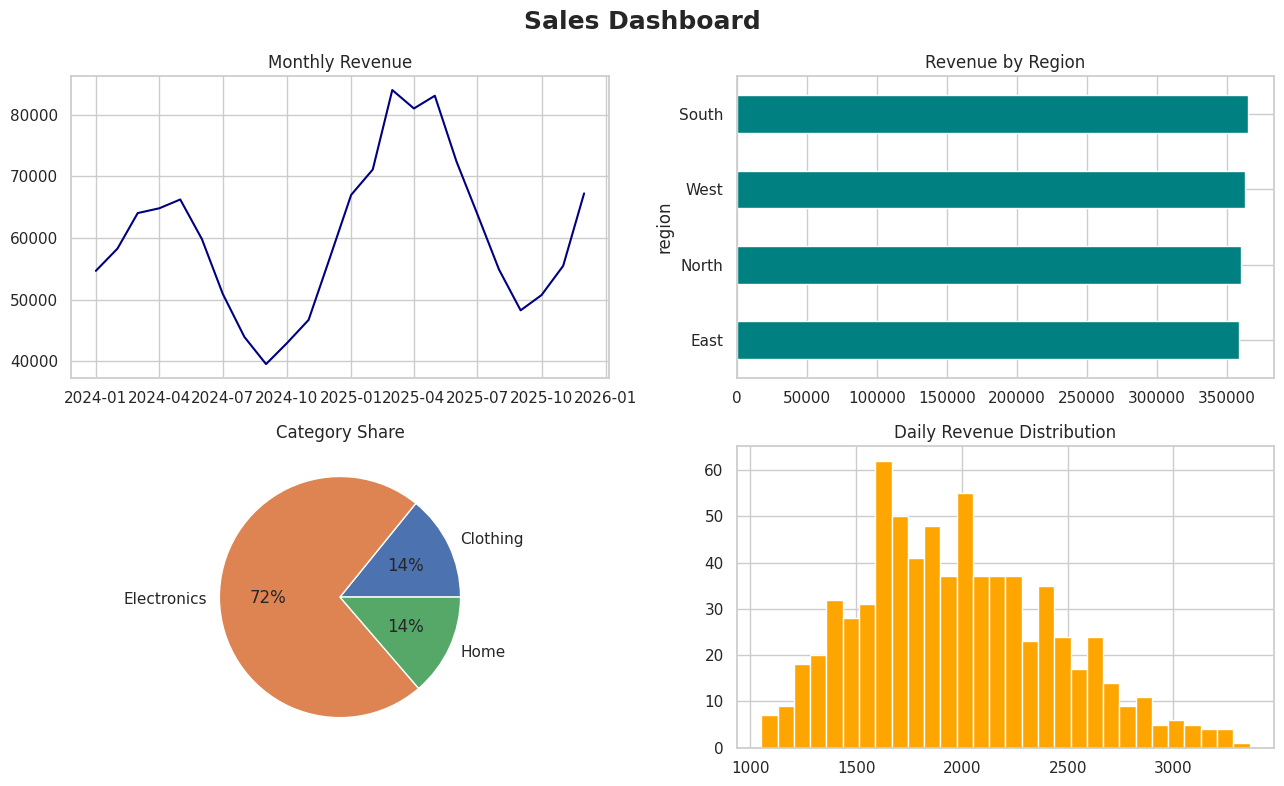

In [10]:
fig, ax = plt.subplots(2, 2, figsize=(13, 8))
fig.suptitle('Sales Dashboard', fontsize=18, fontweight='bold')

ax[0, 0].plot(monthly.index, monthly.values, color='navy')
ax[0, 0].set_title('Monthly Revenue')

reg.plot.barh(ax=ax[0, 1], color='teal')
ax[0, 1].set_title('Revenue by Region')

cat_total = sales.groupby('category')['revenue'].sum()
ax[1, 0].pie(cat_total, labels=cat_total.index, autopct='%1.0f%%')
ax[1, 0].set_title('Category Share')

ax[1, 1].hist(daily, bins=30, color='orange', edgecolor='white')
ax[1, 1].set_title('Daily Revenue Distribution')

plt.tight_layout()
plt.savefig('images/sales_dashboard.png', dpi=130)
plt.show()

## Part D - Interactive Plotly dashboard
The KPI numbers come from the data; hover and zoom on any chart.

In [11]:
total_rev = sales['revenue'].sum()
total_units = sales['units'].sum()
best_region = reg.idxmax()
print(f'Total revenue: ${total_rev:,.0f} | Units sold: {total_units:,} | Best region: {best_region}')

fig = make_subplots(
    rows=2, cols=2,
    specs=[[{'type': 'xy'}, {'type': 'xy'}], [{'type': 'domain'}, {'type': 'xy'}]],
    subplot_titles=('Monthly Revenue', 'Revenue by Region', 'Category Share', 'Revenue by Month and Category'))

fig.add_trace(go.Scatter(x=monthly.index, y=monthly.values, mode='lines+markers', name='Revenue'), row=1, col=1)
fig.add_trace(go.Bar(x=reg.index, y=reg.values, name='Region', marker_color='teal'), row=1, col=2)
fig.add_trace(go.Pie(labels=cat_total.index, values=cat_total.values, name='Category'), row=2, col=1)
for c in cat_month.columns:
    fig.add_trace(go.Bar(x=cat_month.index, y=cat_month[c], name=c), row=2, col=2)

fig.update_layout(height=750, barmode='stack',
                  title_text=f'Sales Dashboard | Total ${total_rev:,.0f} | Best region: {best_region}')
fig.write_html('html_exports/sales_dashboard.html')
fig.show()

Total revenue: $1,447,352 | Units sold: 94,350 | Best region: South


### Dashboard with a dropdown filter

In [12]:
monthly_reg = sales.groupby(['month', 'region'], as_index=False)['revenue'].sum()
fig = go.Figure()
regions = ['All'] + sorted(sales['region'].unique())
for r in regions:
    d = monthly if r == 'All' else monthly_reg[monthly_reg['region'] == r].set_index('month')['revenue']
    fig.add_trace(go.Scatter(x=d.index, y=d.values, name=r, visible=(r == 'All')))

buttons = [dict(label=r, method='update',
                args=[{'visible': [x == r for x in regions]}, {'title': f'Monthly Revenue: {r}'}])
           for r in regions]
fig.update_layout(updatemenus=[dict(buttons=buttons, x=0.0, y=1.15)], title='Monthly Revenue: All')
fig.write_html('html_exports/dashboard_with_filter.html')
fig.show()

### Interactive explorer: animated revenue by region

In [13]:
ra = sales.groupby(['month', 'region'], as_index=False)['revenue'].sum()
ra['month_str'] = ra['month'].dt.strftime('%Y-%m')
fig = px.bar(ra, x='region', y='revenue', color='region', animation_frame='month_str',
             range_y=[0, ra['revenue'].max() * 1.1], title='Revenue by Region, Month by Month')
fig.write_html('html_exports/animated_revenue.html')
fig.show()